# Thermal drift of X, open loop

Analysis of a run of `encoder_thermal_drift_open_loop.py`. Every sample is one CSV row with two photos:
`before` (the drift since the last sample, nothing compensated yet) and `after` (after the compensation, if there was one).

1. **image**: per photo, the centre of the black dot; its shift from the first photo of the run
2. **plot**: that shift over time, next to the encoder (`dUmBefore`, `dUmAfter`)

In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

DATA_DIR = Path("encoder_test_data")          # next to this notebook
PLOT_DIR = DATA_DIR / "encoder_test_plots"   # the plots are saved here
PLOT_DIR.mkdir(exist_ok=True)

# the run: CSV of encoder_thermal_drift_open_loop.py, its photos are in <RUN>_photos/before and /after
RUN = "encoder_thermal_drift_open_loop_x_20261022_110649"
CSV = DATA_DIR / f"{RUN}.csv"
PHOTO_DIR = DATA_DIR / f"{RUN}_photos"
IMAGE_CSV = DATA_DIR / f"{RUN}_image.csv"   # written by the image cell
RADIUS = 400
UM_PER_PX = 0.1192      # pixel size on the calibration slide (10 um ruler period = 83.9 px)
# SIGN = +1 if + steps move the dot to +x in the picture, -1 if the other way
SIGN = 1

COLOR = "#eb6834"       # linear encoder, as the 24 h linear run

## 1. Image: shift of the dot

Per photo, the centre of the black dot: the mean position of all pixels darker than DARK, leaving out
BORDER pixels at the image edges (the edge of the field of view is dark too).
The shift is that centre minus the centre in the first `before` photo (sample 0), in um.
`dot_px` is the dot area, about the same in every photo; a jump means the dot was not found well.
A missing photo (empty field in the CSV) gives an empty row.
One row per sample, written to `<RUN>_image.csv`.

In [12]:
samples = pd.read_csv(CSV, comment="#", usecols=["sample", "elapsed_s", "dUmBefore", "dUmAfter",
                                                  "photoBefore", "photoAfter"])

DARK = 50      # grey value: darker pixels belong to the black dot
BORDER = 500   # [px] left out at the image edges, which are dark too

for side in ["Before", "After"]:
    centres = []
    for photo in samples[f"photo{side}"]:
        if pd.isna(photo):   # no photo at this sample
            centres.append((np.nan, np.nan, 0))
            continue
        # the CSV has the full path of the PC that took it: only the file name is used
        img = np.asarray(Image.open(PHOTO_DIR / side.lower() / Path(photo).name).convert("L"))
        y, x = np.nonzero(img[BORDER:-BORDER, BORDER:-BORDER] < DARK)
        # rough centre: the median is not pulled by the marks on the slide
        x_mid, y_mid = np.median(x), np.median(y)
        # keep only the dark pixels near the dot
        near = (x - x_mid) ** 2 + (y - y_mid) ** 2 < RADIUS ** 2
        x, y = x[near], y[near]
        centres.append((BORDER + x.mean(), BORDER + y.mean(), len(x)))

    samples[[f"x{side}_px", f"y{side}_px", f"dot{side}_px"]] = centres

# reference: the dot in the first before photo
x0, y0 = samples.xBefore_px[0], samples.yBefore_px[0]
for side in ["Before", "After"]:
    samples[f"dx{side}_um"] = SIGN * (samples[f"x{side}_px"] - x0) * UM_PER_PX
    samples[f"dy{side}_um"] = (samples[f"y{side}_px"] - y0) * UM_PER_PX

samples = samples.drop(columns=["photoBefore", "photoAfter"])
samples.to_csv(IMAGE_CSV, index=False)
samples.round(2)

,sample,elapsed_s,dUmBefore,dUmAfter,xBefore_px,yBefore_px,dotBefore_px,xAfter_px,yAfter_px,dotAfter_px,dxBefore_um,dyBefore_um,dxAfter_um,dyAfter_um
0,0,0.0,0.00,0.00,2321.00,1903.78,278730.0,2321.00,1903.79,278730.0,0.00,0.00,0.00,0.00
1,1,300.0,0.00,0.00,2322.37,1901.24,278907.0,2322.42,1901.22,278932.0,0.16,-0.30,0.17,-0.31
2,2,600.0,1.95,0.00,2324.19,1898.37,279097.0,2324.18,1898.37,279104.0,0.38,-0.65,0.38,-0.65
3,3,900.0,1.95,0.00,2326.62,1894.92,279736.0,2326.63,1894.88,279715.0,0.67,-1.06,0.67,-1.06
4,4,1200.0,0.00,0.00,2328.49,1893.87,280300.0,2328.48,1893.88,280345.0,0.89,-1.18,0.89,-1.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,164,49200.0,3.91,1.95,1920.46,1941.31,278571.0,1920.46,1941.34,278532.0,-47.74,4.47,-47.74,4.48
165,165,49500.0,3.91,1.95,1918.80,1940.92,278588.0,1918.82,1940.89,278630.0,-47.94,4.43,-47.94,4.42
166,166,49800.0,3.91,3.91,1917.26,1940.61,278694.0,1917.23,1940.66,278691.0,-48.13,4.39,-48.13,4.40
167,167,50100.0,3.91,3.91,1915.68,1940.30,278757.0,1915.64,1940.30,278751.0,-48.31,4.35,-48.32,4.35


## 2. Plot

Shift of the dot over the run, along x (the X axis) and along y.
Image: filled = before, open = after the compensation. Encoder: dashed, in steps of 1.95 um.

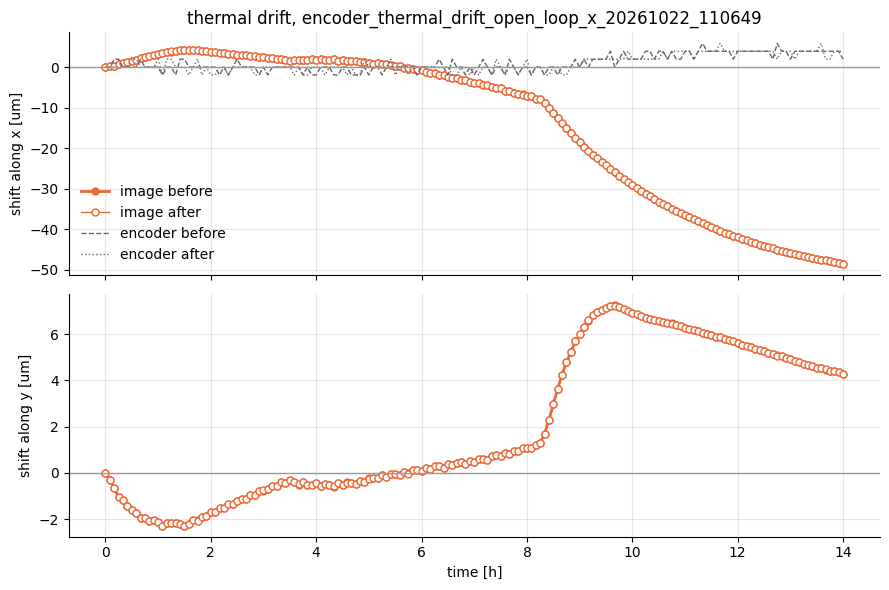

In [13]:
samples = pd.read_csv(IMAGE_CSV)
hours = samples.elapsed_s / 3600

fig, (ax_x, ax_y) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax_x.plot(hours, samples.dxBefore_um, "o-", color=COLOR, lw=2, ms=5, label="image before")
ax_x.plot(hours, samples.dxAfter_um, "o-", color=COLOR, lw=1, ms=5, mfc="white", label="image after")
ax_x.plot(hours, samples.dUmBefore, "--", color="0.4", lw=1, label="encoder before")
ax_x.plot(hours, samples.dUmAfter, ":", color="0.4", lw=1, label="encoder after")
ax_x.set_ylabel("shift along x [um]")
ax_x.legend(frameon=False)

ax_y.plot(hours, samples.dyBefore_um, "o-", color=COLOR, lw=2, ms=5, label="image before")
ax_y.plot(hours, samples.dyAfter_um, "o-", color=COLOR, lw=1, ms=5, mfc="white", label="image after")
ax_y.set_ylabel("shift along y [um]")
ax_y.set_xlabel("time [h]")

for ax in (ax_x, ax_y):
    ax.axhline(0, color="0.6", lw=1)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
ax_x.set_title(f"thermal drift, {RUN}")
fig.tight_layout()
fig.savefig(PLOT_DIR / f"{RUN}.png", dpi=150)
plt.show()